# SVM lineal sobre la muestra inicial de Lending Club

**Experimento complementario:** comparación de regresión logística, `LinearSVC`, árbol e HistGradientBoosting con una **matriz transformada común**. La receta conserva la muestra inicial de 220,003 préstamos, semilla 42 y los periodos 2007–2014 / 2015–2016 / 2017–2018. Cada fila es un préstamo y el objetivo es `Fully Paid = 0`, `Charged Off = 1`.

Procede de `feat/cierre-svm-validacion`, commit `a189be8`. El notebook aportado no tenía celdas ejecutadas ni archivos de métricas SVM publicados. La primera ejecución real autorizada se completó el 18 de noviembre de 2026: los resultados están en `outputs/svm_muestra/`. La consulta muestra esa referencia sin volver a entrenar.

**Pregunta predictiva del proyecto:** Dado un préstamo que Lending Club acaba de aprobar, y usando únicamente la información disponible el día del desembolso, ¿qué probabilidad hay de que termine declarado incobrable (`Charged Off`) en lugar de pagarse por completo (`Fully Paid`)? En esta etapa `LinearSVC` entrega un margen de riesgo sin calibrar: no responde todavía con probabilidades calibradas. El SVM calibrado del pipeline final pertenece a otra etapa y otra población.

## 1. Configuración inicial del entorno

Localizamos el proyecto sin cargar el CSV. Las operaciones del experimento están en `src/svm_muestra.py`; no sustituyen el pipeline final.

In [2]:
from pathlib import Path
import os
import sys

base = Path(os.environ.get("PROYECTO_ML_RAIZ", Path.cwd())).resolve()
RAIZ = next((p for p in [base, *base.parents] if (p / "src/config.py").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("Abra Jupyter dentro del proyecto o defina PROYECTO_ML_RAIZ.")
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

### Control de ejecución: consulta o reproducción

`REPRODUCIR = False` permite consultar las tablas, configuraciones y figuras históricas. En este modo no se carga el CSV original ni se entrenan modelos, buscan hiperparámetros o recalibran probabilidades. Si falta algún resultado histórico, el notebook indica qué archivo o sección no está disponible; no ejecuta un entrenamiento para reemplazarlo.

Para repetir el experimento, cambia a `REPRODUCIR = True` y ejecuta todas las celdas en orden después de reiniciar el kernel. El notebook cargará el CSV y repetirá el experimento con los periodos, las semillas y la preparación definidos.

`RUTA_DATOS` indica **dónde está el archivo CSV** que se usará para reproducir el experimento. Si el archivo está en una ubicación habitual del proyecto, deja `RUTA_DATOS = None` para que el notebook lo localice. Si está en otra ubicación, escribe la ruta completa al archivo, por ejemplo:

```python
RUTA_DATOS = r"C:\datos\accepted_loans.csv"
```

La primera referencia histórica ya está guardada y vinculada a su ejecución independiente. Las reproducciones futuras se compararán contra ella y no la reemplazarán automáticamente.

In [3]:
REPRODUCIR = False
RUTA_DATOS = None

In [4]:
import json
import pandas as pd
from IPython.display import Image, display
from src import svm_muestra as svm
from src.experimento_inicial import cargar_experimento_inicial
from src.reproduccion_notebooks import SesionNotebook

ORIGEN = RAIZ / "outputs/svm_muestra"
sesion = SesionNotebook(RAIZ, "05_svm", REPRODUCIR, RUTA_DATOS)
SALIDA = sesion.salida if REPRODUCIR else ORIGEN
PARES_VERIFICACION = [(ORIGEN / nombre, SALIDA / nombre) for nombre in svm.ARCHIVOS_VERIFICABLES]
sesion.requerir([p for p, _ in PARES_VERIFICACION if p.is_file()])

def exigir_reproduccion():
    if not REPRODUCIR or not sesion.reproducir:
        raise RuntimeError("Reinicia el kernel con REPRODUCIR = True para reproducir.")
    sesion.exigir()
    if SALIDA != sesion.salida:
        raise RuntimeError("No cambies el destino de reproducción a una carpeta histórica.")

def falta_referencia(nombre):
    print("No verificable con la evidencia disponible: falta", ORIGEN / nombre)
    print("Es necesario recuperar la referencia SVM publicada o revisar una nueva ejecución; no se entrenará automáticamente para reemplazarla.")

if not REPRODUCIR and not (ORIGEN / "metricas_svm_muestra.csv").is_file():
    falta_referencia("metricas_svm_muestra.csv")

Modo consulta: resultados históricos guardados. No se ha ejecutado una nueva reproducción.


## 2. Carga y verificación de la muestra

La reproducción utiliza `cargar_experimento_inicial`, compartido con 02–03, que llama una sola vez al muestreador original y mantiene el objetivo 220,000 sin recortar el redondeo de 220,003. Conserva `Fully Paid` y `Charged Off`, bloques de 50,000 y semilla `42 + índice del bloque`. Después divide por los cortes 2015 y 2017.

En consulta, si no existe la auditoría SVM, se presenta únicamente la auditoría histórica de la muestra inicial como contexto. No demuestra que se haya entrenado SVM. Se contrastan cantidades y prevalencias con esa referencia al reproducir; las nuevas huellas de IDs registran el orden de las observaciones, sin suponer que métricas iguales prueban identidad.

In [5]:
if REPRODUCIR:
    exigir_reproduccion()
    experimento = svm.cargar_muestra(RUTA_DATOS, RAIZ)
    resumen_particiones = svm.resumen_particiones(experimento)
    display(resumen_particiones)
else:
    experimento = None
    if (ORIGEN / "particiones_svm_muestra.csv").is_file():
        resumen_particiones = pd.read_csv(ORIGEN / "particiones_svm_muestra.csv")
        print("Particiones de la ejecución histórica SVM:")
        display(resumen_particiones)
    else:
        print("Contexto de la muestra inicial de 01–03; no es evidencia de entrenamiento SVM:")
        contexto = cargar_experimento_inicial(modo="consulta", raiz=RAIZ)
        display(contexto["resumen"])
        falta_referencia("particiones_svm_muestra.csv")

Particiones de la ejecución histórica SVM:


,conjunto,filas,anio_min,anio_max,default_pct
0,entrenamiento,73701,2007,2014,16.868156
1,validacion,109382,2015,2016,21.344463
2,prueba,36920,2017,2018,21.245937


## 3. Preparación compartida sin fuga de información

Se conserva `logistica_sin_indicadores`: excluye identificadores, texto fuera de alcance, precio/calificación LC e información posterior al préstamo. Las variables con **más de 95% de faltantes en entrenamiento** se excluyen. Medianas, categorías, codificación y escalas se aprenden solo con 2007–2014, y se aplican a validación y prueba. Se rellenan categorías con `Sin información`, se usa One-Hot con categoría de referencia y se escalan las numéricas. La fecha de crédito se transforma en antigüedad. No se agregan indicadores.

Los cuatro modelos reciben exactamente las mismas filas y columnas transformadas. Se prepara solo ese escenario; no se construyen las dos matrices logísticas que este experimento no utiliza.

Esta comparación controla el preprocesamiento, pero **no reproduce exactamente 02 ni 03**: esos notebooks conservan NaN numéricos, no escalan y emplean One-Hot completo con agrupamiento de categorías infrecuentes. Además, el Boosting de este notebook conserva una configuración fija de 75 iteraciones, mientras 03 usa una grilla de 108 configuraciones. Las diferencias miden estrategias distintas; ninguna preparación se declara universalmente mejor.

In [6]:
if REPRODUCIR:
    exigir_reproduccion()
    datos = svm.preparar_variables(experimento)
    display(pd.Series(datos["variables"], name="Preparación de la sesión actual"))
    display(pd.DataFrame({"variable_transformada": datos["X"]["entrenamiento"].columns}))
else:
    datos = None
    for nombre in ["variables_svm_muestra.csv", "columnas_transformadas.csv"]:
        if (ORIGEN / nombre).is_file():
            display(pd.read_csv(ORIGEN / nombre))
        else:
            falta_referencia(nombre)

,variable,porcentaje_faltante_train,decision
0,mths_since_last_record,86.728810,imputar
1,mths_since_recent_bc_dlq,78.486045,imputar
2,mths_since_last_major_derog,78.416846,imputar
3,mths_since_recent_revol_delinq,69.890504,imputar
4,mths_since_last_delinq,53.594931,imputar
...,...,...,...
60,dti,0.000000,imputar
61,fico_range_low,0.000000,imputar
62,delinq_2yrs,0.000000,imputar
63,delinq_amnt,0.000000,imputar


,variable
0,loan_amnt
1,term
2,annual_inc
3,dti
4,delinq_2yrs
...,...
133,addr_state_VT
134,addr_state_WA
135,addr_state_WI
136,addr_state_WV


## 4. Modelos, parámetros y entrenamiento

Se mantienen los parámetros del notebook aportado:

| Modelo | Configuración fijada |
|---|---|
| Regresión logística | `C=1.0`, `solver="lbfgs"`, `max_iter=2000` |
| LinearSVC | `C=0.010053940194693016`, `class_weight="balanced"`, `dual="auto"`, `max_iter=7000` |
| Árbol de decisión | `max_depth=10`, `min_samples_leaf=1000` |
| HistGradientBoosting | `max_iter=75`, `max_leaf_nodes=15`, `learning_rate=0.08`, `l2_regularization=1.0`, `early_stopping=False` |

Todos conservan `random_state=42`. Los demás parámetros son los valores predeterminados del estimador de la versión instalada; la configuración completa y versiones quedan registradas. No se hace otra búsqueda. El parámetro C del SVM procede de la búsqueda temporal previa del proyecto: esta comparación es exploratoria y su validación no debe presentarse como independiente de todas las decisiones anteriores.

Cada clasificador se ajusta una sola vez. Para SVM se conserva `decision_function`, que puede devolver valores negativos o mayores que uno. Ese margen **no es una probabilidad**. Los otros clasificadores utilizan `predict_proba` para sus puntuaciones.

In [7]:
if REPRODUCIR:
    exigir_reproduccion()
    metricas, modelos, scores, y = svm.entrenar_modelos(datos)
    svm.guardar_resultados(SALIDA, experimento, datos, metricas)
else:
    modelos = scores = y = None
    metricas = pd.read_csv(ORIGEN / "metricas_svm_muestra.csv") if (ORIGEN / "metricas_svm_muestra.csv").is_file() else None
    if (ORIGEN / "configuracion_svm_muestra.json").is_file():
        configuracion_historica = json.loads((ORIGEN / "configuracion_svm_muestra.json").read_text(encoding="utf-8"))
        display(configuracion_historica)
    else:
        print("Configuración prevista en el código; no representa modelos entrenados:")
        display(pd.DataFrame([{"modelo": n, "parametros": p} for n, p in svm.configuracion_experimento()["modelos"].items()]))
        falta_referencia("configuracion_svm_muestra.json")

{'commit_origen': 'a189be888955c925eef1473c8e6777f9c6342ee8',
 'notebook_origen': 'notebooks/11_svm_muestra.ipynb',
 'notebook_actual': 'notebooks/05_svm_muestra.ipynb',
 'semilla': 42,
 'bloque': 50000,
 'tamano_muestra_objetivo': 220000,
 'filas_muestra_esperadas': 220003,
 'cortes': {'validacion': 2015, 'prueba': 2017},
 'preprocesamiento': {'escenario': 'logistica_sin_indicadores',
  'indicadores_faltantes': False,
  'precio_lc': False,
  'umbral_excluir_faltantes_pct': 95,
  'fit_solo_entrenamiento': True,
  'numericas': 'mediana y StandardScaler',
  'categoricas': "Sin información y OneHotEncoder(drop='first', handle_unknown='ignore')",
  'matriz_compartida': True},
 'modelos': {'regresion_logistica': {'C': 1.0,
   'class_weight': None,
   'dual': False,
   'fit_intercept': True,
   'intercept_scaling': 1,
   'l1_ratio': 0.0,
   'max_iter': 2000,
   'n_jobs': None,
   'penalty': 'deprecated',
   'random_state': 42,
   'solver': 'lbfgs',
   'tol': 0.0001,
   'verbose': 0,
   'warm

## 5. Métricas y umbral de clasificación

ROC-AUC y Average Precision (AP) se calculan sobre puntuaciones continuas; en SVM, sobre el margen. Para precisión, recall, F1 y accuracy se elige el umbral que maximiza F1 **solo en validación** y se congela para los tres periodos. El test no interviene en esa elección. No se calculan Brier Score ni Log Loss sobre márgenes sin calibrar.

Se muestran primero entrenamiento y validación. Los tiempos informan del costo computacional y pueden cambiar entre equipos; no se usan para rechazar una reproducción.

In [8]:
if metricas is not None:
    print("Resultados de esta reproducción:" if REPRODUCIR else "Resultados históricos guardados:")
    display(metricas[metricas["conjunto"] != "prueba"].round(6))
    print("Rendimiento computacional informativo; no exige coincidencia de tiempos:")
    display(metricas[metricas["conjunto"] == "entrenamiento"][["modelo", "segundos_entrenamiento"]])
else:
    falta_referencia("metricas_svm_muestra.csv")

Resultados históricos guardados:


,modelo,conjunto,n,ROC_AUC,AP,umbral_validacion,precision,recall,F1,accuracy,VN,FP,FN,VP,segundos_entrenamiento
0,regresion_logistica,entrenamiento,73701,0.702498,0.323402,0.175377,0.277314,0.617198,0.382684,0.664116,41273,19996,4759,7673,1.702188
1,regresion_logistica,validacion,109382,0.712053,0.401609,0.175377,0.343986,0.634386,0.446088,0.663729,57789,28246,8536,14811,1.702188
3,svm_lineal,entrenamiento,73701,0.702068,0.320991,0.027112,0.279216,0.605373,0.382166,0.669828,41841,19428,4906,7526,5.627479
4,svm_lineal,validacion,109382,0.712178,0.400789,0.027112,0.345993,0.625091,0.445435,0.667779,58449,27586,8753,14594,5.627479
6,arbol_decision,entrenamiento,73701,0.685582,0.295629,0.169217,0.253473,0.667712,0.367455,0.612230,36821,24448,4131,8301,1.278131
7,arbol_decision,validacion,109382,0.672817,0.350725,0.169217,0.309708,0.623249,0.413792,0.623082,53603,32432,8796,14551,1.278131
9,gradient_boosting,entrenamiento,73701,0.731089,0.365499,0.181274,0.296908,0.643420,0.406319,0.682840,42327,18942,4433,7999,1.927117
10,gradient_boosting,validacion,109382,0.710608,0.402719,0.181274,0.346954,0.616096,0.443916,0.670540,58961,27074,8963,14384,1.927117


Rendimiento computacional informativo; no exige coincidencia de tiempos:


,modelo,segundos_entrenamiento
0,regresion_logistica,1.702188
3,svm_lineal,5.627479
6,arbol_decision,1.278131
9,gradient_boosting,1.927117


### Evaluación de prueba con las decisiones ya fijadas

La tabla conserva el orden de los cuatro modelos; no elige un ganador a partir del test. Corresponde a 2017–2018 de la muestra inicial, cuyo test ya se utilizó en etapas anteriores: su análisis es retrospectivo y no una nueva evaluación independiente.

In [9]:
if metricas is not None:
    resumen_test = metricas[metricas["conjunto"] == "prueba"].set_index("modelo").reindex(svm.NOMBRES)
    display(resumen_test.round(6))
else:
    falta_referencia("metricas_svm_muestra.csv")

,conjunto,n,ROC_AUC,AP,umbral_validacion,precision,recall,F1,accuracy,VN,FP,FN,VP,segundos_entrenamiento
modelo,,,,,,,,,,,,,,
regresion_logistica,prueba,36920,0.690191,0.358399,0.175377,0.334765,0.576364,0.423533,0.666658,20092,8984,3323,4521,1.702188
svm_lineal,prueba,36920,0.690612,0.357552,0.027112,0.333633,0.567695,0.420273,0.667254,20182,8894,3391,4453,5.627479
arbol_decision,prueba,36920,0.638469,0.302884,0.169217,0.291386,0.563233,0.384074,0.616197,18332,10744,3426,4418,1.278131
gradient_boosting,prueba,36920,0.685960,0.357190,0.181274,0.334861,0.540413,0.413500,0.674296,20656,8420,3605,4239,1.927117


## 6. Curvas ROC y Precision–Recall

Se dibujan con las puntuaciones de la nueva sesión solo en reproducción. En consulta se abre la imagen histórica si existe; no se reconstruyen curvas a partir de AUC agregadas.

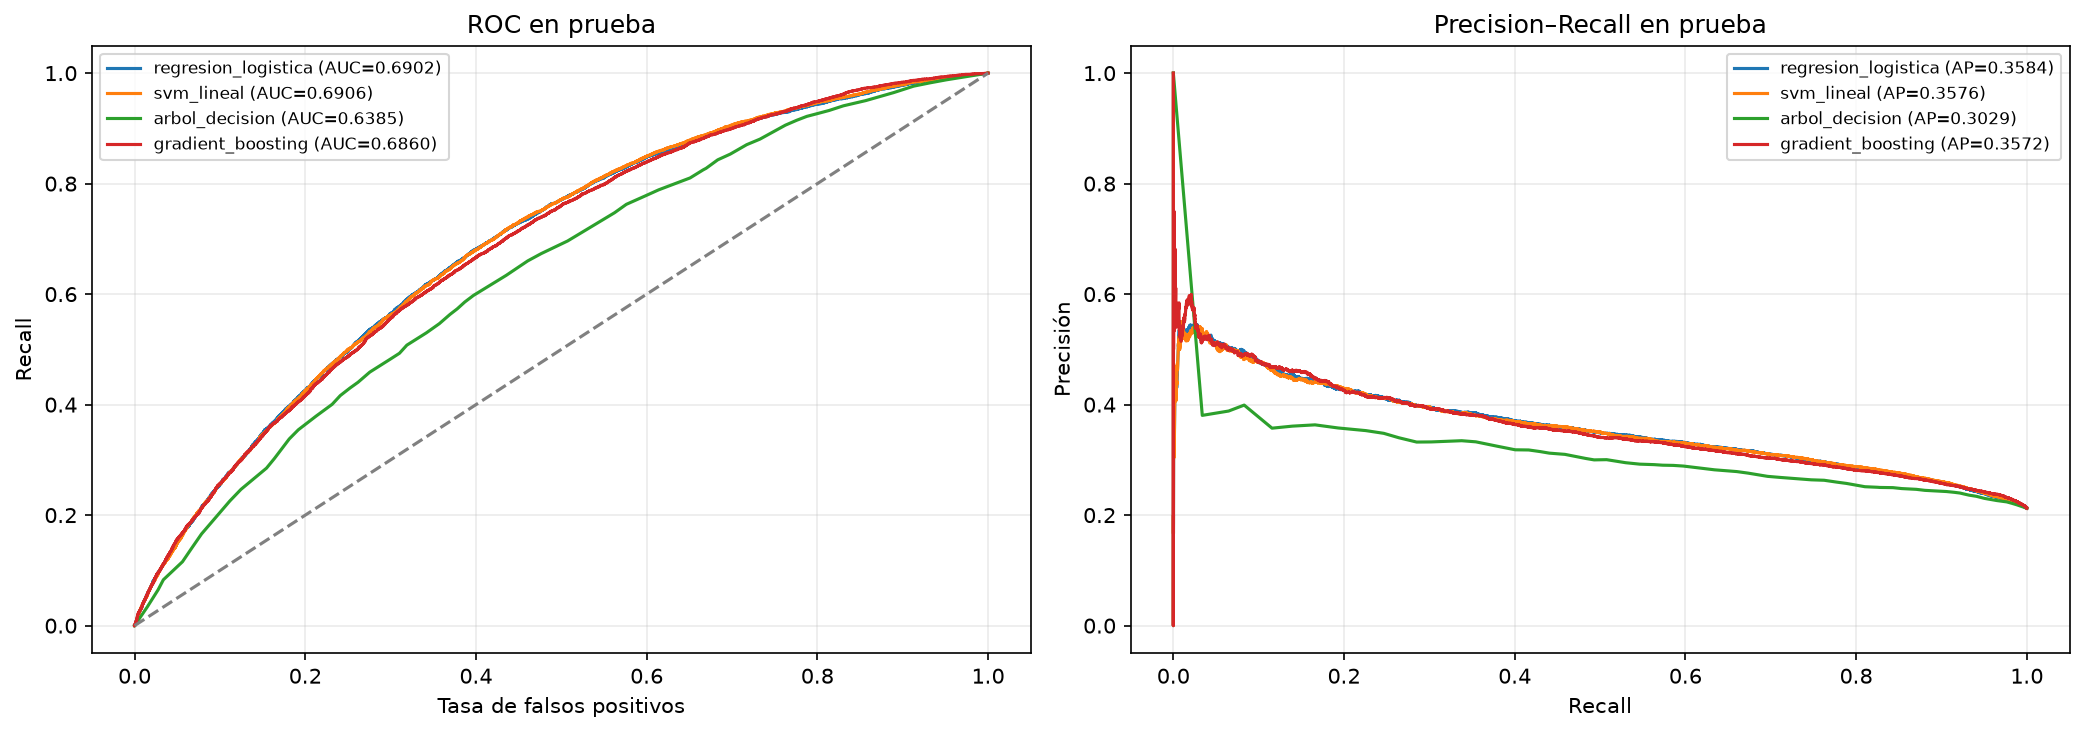

In [10]:
if REPRODUCIR:
    exigir_reproduccion()
    import matplotlib.pyplot as plt
    fig = svm.graficar_curvas(scores, y, SALIDA)
    display(fig)
    plt.close(fig)
else:
    if (ORIGEN / "curvas_svm_muestra.png").is_file():
        display(Image(filename=str(ORIGEN / "curvas_svm_muestra.png")))
    else:
        falta_referencia("curvas_svm_muestra.png")

## 7. Conclusiones y alcance

- Las cuatro estrategias se comparan dentro de este experimento con el mismo preprocesamiento; no se les atribuyen las métricas específicas de 02–03.
- El margen de SVM permite ordenar riesgo, pero no expresa la probabilidad individual de incumplimiento. Aquí no se calibra ni se evalúa como si lo estuviera.
- El umbral procede de F1 en validación y no se reajusta con prueba. Los parámetros son fijos y heredados; no se afirma haber encontrado un óptimo nuevo.
- Este SVM usa la muestra inicial. El SVM final utiliza todo el desarrollo, selección temporal al 50%, entrenamiento base hasta 2015 y calibración sigmoide en 2016. Sus métricas y poblaciones no son intercambiables.
- La primera sesión real se conserva como referencia inicial. En validación, SVM obtuvo ROC-AUC 0.712178 y AP 0.400789, frente a 0.712053 y 0.401609 de logística. La diferencia de AUC es mínima y no demuestra una mejora significativa. Aún no es una comparación contra otra ejecución SVM independiente.
- Solo se observan préstamos aceptados con resultado final conocido. La maduración de préstamos recientes y el test ya consultado limitan la interpretación.

## Verificación de reproducibilidad

Se comparan observaciones y años por partición, variables originales/transformadas, configuración, semillas, ROC-AUC, AP, precisión, recall, F1 y umbrales. El archivo de la muestra registra huellas de IDs cuando están disponibles. Se usa el comparador común: `atol=1e-8`, `rtol=1e-6` en reales, igualdad exacta en enteros y etiquetas, sin redondear antes de comparar. `segundos_entrenamiento` es informativo y queda excluido del criterio de coincidencia.

**Coincide** y **Difiere** requieren ejecución y referencia disponible. **No verificado** indica consulta. **No verificable** señala falta de evidencia. Sin referencias propias SVM, las métricas de los otros notebooks no las sustituyen; aun después de una primera ejecución los elementos sin referencia siguen siendo no verificables.

In [11]:
if REPRODUCIR != sesion.reproducir:
    raise RuntimeError("Reinicia el kernel para cambiar el modo de ejecución.")
verificacion = sesion.finalizar(
    PARES_VERIFICACION,
    configuracion=svm.configuracion_experimento() if REPRODUCIR else None,
    datos=experimento["ruta"] if REPRODUCIR else None,
)
if not REPRODUCIR and not (ORIGEN / "metricas_svm_muestra.csv").is_file():
    verificacion = pd.concat([verificacion, pd.DataFrame([{
        "Elemento": "Referencia del experimento SVM sobre muestra", "Original": None,
        "Reproducido": None, "Diferencia": "No existe una primera ejecución oficial publicada.",
        "Estado": "No verificable"}])], ignore_index=True)
display(verificacion)
print("Resumen de verificación:", verificacion["Estado"].value_counts().to_dict())

,Elemento,Original,Reproducido,Diferencia,Estado
0,Reproducción,null,null,Solo se consultaron resultados históricos.,No verificado


Resumen de verificación: {'No verificado': 1}
